In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Training/pituitary/Tr-pi_124.jpg
/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Training/pituitary/Tr-pi_949.jpg
/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Training/pituitary/Tr-pi_786.jpg
/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Training/pituitary/Tr-pi_371.jpg
/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Training/pituitary/Tr-pi_599.jpg
/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Training/pituitary/Tr-pi_802.jpg
/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Training/pituitary/Tr-pi_1323.jpg
/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Training/pituitary/Tr-pi_1347.jpg
/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Training/pituitary/Tr-pi_955.jpg
/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Training/pituitary/Tr-pi_778.jpg
/kaggle/input/datasets/masou

1. Configuração do ambiente

In [2]:
!pip install -q kagglehub imagehash

import copy, json, random, time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import imagehash
from PIL import Image
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, confusion_matrix
from sklearn.model_selection import ParameterGrid, StratifiedGroupKFold, train_test_split
from torch.utils.data import DataLoader, Dataset
from torchvision import models
from torchvision.transforms import v2

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"   # precisão mista: ~2x mais rápido na T4, sem mudar o resultado na prática
print("Dispositivo:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU")

def seed_everything(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

SEED = 42
seed_everything(SEED)

Dispositivo: cuda | Tesla T4


### Parâmetros do experimento



> Se mudar `IMG_SIZE`, `GRID_TRAIN_FRACTION`, as épocas ou a divisão, apague o `grid_search.csv` antes: a retomada identifica cada configuração só pelos hiperparâmetros do `PARAM_GRID`.

In [3]:
# --- Dados ---
KAGGLE_DATASET = "masoudnickparvar/brain-tumor-mri-dataset"   # mesmo dataset do notebook de referência
DATA_DIR = None          # None = baixa do Kaggle; ou um caminho local com Training/ e Testing/
CLASSES = ["glioma", "meningioma", "notumor", "pituitary"]
IMG_SIZE = 224           # resolução de pré-treino da ResNet18
SPLIT = (0.70, 0.15, 0.15)
N_FOLDS = 20             # a divisão é feita em 20 "fatias" de 5%: 14 treino, 3 validação, 3 teste
DUP_HAMMING = 4          # distância máxima entre pHashes (de 64 bits) para considerar duas imagens quase idênticas

# --- Modelo ---
PRETRAINED = True        # pesos ResNet18_Weights.DEFAULT (ImageNet)
BATCH_SIZE = 32
WEIGHT_DECAY = 1e-4      # regularização L2 leve nos pesos
BACKBONE_LR_MULT = 0.1   # lr do backbone = lr da cabeça × 0,1
WARMUP_EPOCHS = 1        # épocas só com a cabeça antes do fine-tuning

# --- Grid search ---
PARAM_GRID = {
    "lr":         [1e-3, 1e-4],
    "fine_tune":  ["fc", "layer4", "layer3"],   # quais blocos convolucionais são ajustados (ver seção 3)
    "dropout":    [0.2, 0.5],
    "optimizer":  ["adamw", "sgd"],
}
GRID_MAX_EPOCHS = 6
GRID_PATIENCE = 2
GRID_TRAIN_FRACTION = 0.5   # o grid usa metade do treino, para acelerar

# --- Treino final ---
FINAL_MAX_EPOCHS = 20
FINAL_PATIENCE = 5
FINAL_SEEDS = [42, 7, 2026]
BASELINE_MAX_EPOCHS = 25    # a CNN do zero precisa de mais épocas

# --- Saídas ---
OUT_DIR = Path("resultados_tumor_mri")
OUT_DIR.mkdir(exist_ok=True)
GRID_CSV = OUT_DIR / "grid_search.csv"

print(f"{len(ParameterGrid(PARAM_GRID))} configurações no grid")

24 configurações no grid


2. DADOS

### 2.1 Download e inventário

O dataset vem com as pastas `Training/` e `Testing/`, cada uma com uma subpasta por classe.  **juntamos tudo** e refazemos a divisão do zero. guardamos a **pasta de origem** de cada imagem (`origem`), para depois medir quanta repetição existia entre o treino e o teste originais.

In [4]:
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

if DATA_DIR is None:
    import kagglehub
    DATA_DIR = kagglehub.dataset_download(KAGGLE_DATASET)
DATA_DIR = Path(DATA_DIR)
print("Dados em:", DATA_DIR)

files = sorted(p for p in DATA_DIR.rglob("*")
               if p.suffix.lower() in IMG_EXTS and p.parent.name.lower() in CLASSES)
df = pd.DataFrame({
    "path":   [str(p) for p in files],
    "label":  [p.parent.name.lower() for p in files],          # classe = nome da pasta
    "origem": [p.parent.parent.name.lower() for p in files],   # training / testing
}).drop_duplicates("path").reset_index(drop=True)

CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}
df["y"] = df["label"].map(CLASS_TO_IDX)

print(f"{len(df)} imagens")
pd.crosstab(df["label"], df["origem"], margins=True, margins_name="total")

Dados em: /kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset
7200 imagens


origem,testing,training,total
label,,,
glioma,400,1400,1800
meningioma,400,1400,1800
notumor,400,1400,1800
pituitary,400,1400,1800
total,1600,5600,7200


### 2.2 Imagens duplicadas e quase idênticas (o *data leakage*)

**A ideia:** se a mesma imagem (ou uma cópia levemente diferente: recortada, com outro brilho, salva em outro formato) aparece **no treino e no teste**, o modelo não precisa generalizar para acertar: basta **lembrar**. A acurácia de teste fica inflada.

**Como detectamos — hash perceptual (pHash):**
1. Cada imagem é reduzida a tons de cinza e resumida em uma "impressão digital" de **64 bits** que descreve sua estrutura geral (as frequências baixas da imagem).
2. Imagens visualmente parecidas têm hashes parecidos, mesmo que os pixels não sejam idênticos.
3. Comparamos os hashes de **todos os pares** e contamos quantos bits diferem (**distância de Hamming**). Distância 0 = praticamente a mesma imagem; até `DUP_HAMMING = 4` (de 64) = quase idênticas.

**Grupos:** se A ≈ B e B ≈ C, as três formam um **grupo** (algoritmo *union-find*). Na divisão (2.3), um grupo inteiro vai sempre para o **mesmo** conjunto. Assim uma imagem nunca tem uma "irmã" no outro lado.

> **Limitação honesta:** o ideal seria agrupar por **paciente** (várias fatias da mesma ressonância), mas o dataset não traz essa informação. O agrupamento por similaridade é a melhor aproximação disponível, e fatias vizinhas muito parecidas acabam no mesmo grupo, o que é o comportamento desejado.

In [5]:
def phash_int(path):
    try:
        with Image.open(path) as im:
            return int(str(imagehash.phash(im.convert("L"))), 16)   # 64 bits -> inteiro
    except Exception as e:   # imagens corrompidas são descartadas
        print("Ignorando", path, "->", e)
        return None

t0 = time.time()
hashes = [phash_int(p) for p in df["path"]]
ok = np.array([h is not None for h in hashes])
df = df[ok].reset_index(drop=True)
H = np.array([h for h in hashes if h is not None], dtype=np.uint64)
print(f"{len(H)} hashes calculados em {time.time() - t0:.0f}s")

7200 hashes calculados em 41s


**Comparação de todos os pares.** Com ~7 mil imagens são ~25 milhões de pares. Fazemos em blocos de 512 linhas com operações vetorizadas do NumPy:
`XOR` entre hashes marca os bits diferentes, e uma tabela de consulta conta quantos bits valem 1 em cada byte.

In [6]:
POPCOUNT = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)   # nº de bits 1 em cada byte

def hamming_rows(a, b):
    """Distância de Hamming entre cada hash de `a` e cada hash de `b` -> matriz (len(a), len(b))."""
    x = np.bitwise_xor(a[:, None], b[None, :])                         # bits diferentes
    return POPCOUNT[x.view(np.uint8)].reshape(len(a), len(b), 8).sum(axis=2)

# --- union-find: junta imagens parecidas no mesmo grupo ---
n = len(H)
parent = np.arange(n)
def find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]
        i = parent[i]
    return i
def union(i, j):
    ri, rj = find(i), find(j)
    if ri != rj:
        parent[max(ri, rj)] = min(ri, rj)

pairs = []
t0 = time.time()
for s in range(0, n, 512):
    d = hamming_rows(H[s:s + 512], H)
    ii, jj = np.nonzero(d <= DUP_HAMMING)
    keep = (ii + s) < jj                      # cada par uma vez, sem comparar a imagem com ela mesma
    for i, j in zip(ii[keep], jj[keep]):
        union(i + s, j)
        pairs.append((i + s, j, int(d[i, j])))
print(f"Comparação concluída em {time.time() - t0:.0f}s")

df["grupo"] = [find(i) for i in range(n)]
pairs_df = pd.DataFrame(pairs, columns=["i", "j", "dist"]).astype(int)
pairs_df["cruza_origem"] = df["origem"].values[pairs_df["i"]] != df["origem"].values[pairs_df["j"]]
pairs_df["mesma_classe"] = df["label"].values[pairs_df["i"]] == df["label"].values[pairs_df["j"]]

tam_grupo = df.groupby("grupo")["path"].transform("size")
print(f"Pares quase idênticos (dist ≤ {DUP_HAMMING}): {len(pairs_df)}  ({(pairs_df['dist'] == 0).sum()} com dist = 0)")
print(f"Imagens que têm pelo menos uma 'irmã': {(tam_grupo > 1).sum()} de {n} ({(tam_grupo > 1).mean():.1%})")
print(f"Pares que cruzam training ↔ testing: {pairs_df['cruza_origem'].sum()}")
print(f"Pares com classes diferentes: {(~pairs_df['mesma_classe']).sum()}")

Comparação concluída em 3s
Pares quase idênticos (dist ≤ 4): 5893  (1930 com dist = 0)
Imagens que têm pelo menos uma 'irmã': 3548 de 7200 (49.3%)
Pares que cruzam training ↔ testing: 2027
Pares com classes diferentes: 47


**Quanto do teste original estava "contaminado"?** Contamos as imagens da pasta `Testing` que têm uma cópia quase idêntica na pasta `Training`. Essas imagens são exatamente o tipo de acerto "fácil" que infla os 99% do notebook de referência.

714 de 1600 imagens do Testing original (44.6%) têm uma cópia quase idêntica no Training.


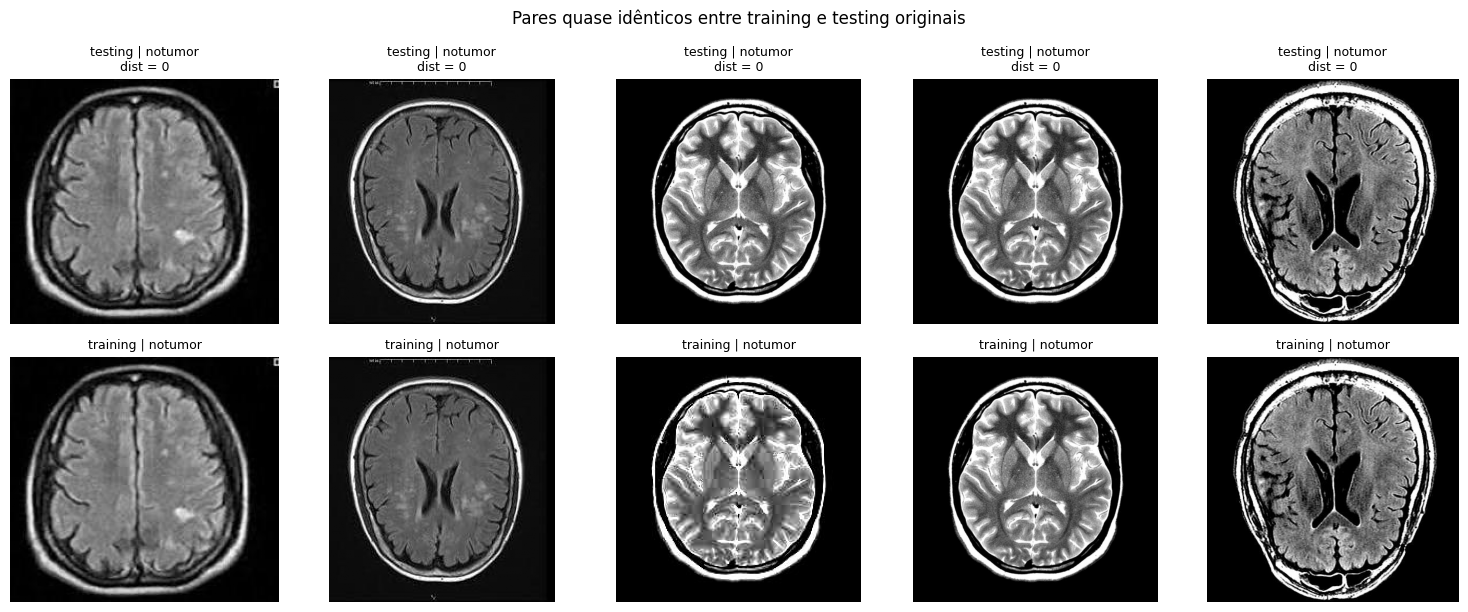

In [7]:
cross = pairs_df[pairs_df["cruza_origem"]]
origem = df["origem"].values
vazadas = set(np.where(origem[cross["i"]] == "testing", cross["i"], cross["j"]))
n_test_orig = (df["origem"] == "testing").sum()
print(f"{len(vazadas)} de {n_test_orig} imagens do Testing original ({len(vazadas) / n_test_orig:.1%}) "
      f"têm uma cópia quase idêntica no Training.")

# Exemplos de pares que cruzam training ↔ testing (em cima e embaixo = um par)
ex = cross.sort_values("dist").head(5)
if len(ex):
    fig, axes = plt.subplots(2, len(ex), figsize=(3 * len(ex), 6.2), squeeze=False)
    for k, r in enumerate(ex.itertuples()):
        for row, idx in enumerate([r.i, r.j]):
            ax = axes[row, k]
            ax.imshow(Image.open(df.loc[idx, "path"]).convert("L"), cmap="gray")
            ax.set_title(f"{df.loc[idx, 'origem']} | {df.loc[idx, 'label']}" + (f"\ndist = {r.dist}" if row == 0 else ""),
                         fontsize=9)
            ax.axis("off")
    plt.suptitle("Pares quase idênticos entre training e testing originais"); plt.tight_layout(); plt.show()

**Grupos com rótulos conflitantes:** se duas imagens quase idênticas têm **classes diferentes**, pelo menos uma delas está com o rótulo errado (ou a imagem é ambígua). Não dá para saber qual, então removemos esses grupos.

In [8]:
conflito = df.groupby("grupo")["label"].transform("nunique") > 1
print(f"Removendo {conflito.sum()} imagens de grupos com rótulos conflitantes")
df = df[~conflito].reset_index(drop=True)

Removendo 124 imagens de grupos com rótulos conflitantes


### 2.3 Divisão fixa, estratificada e **por grupo**: 70% / 15% / 15%

Sortear **grupo por grupo**, mantendo a proporção das classes.

O `StratifiedGroupKFold` faz exatamente isso: divide os dados em `N_FOLDS = 20` fatias de ~5%, cada uma com a mesma proporção de classes e **sem quebrar grupos**. Depois juntamos 14 fatias para o treino (70%), 3 para a validação (15%) e 3 para o teste (15%).

A divisão é feita **uma única vez** com semente fixa e salva em CSV.

In [9]:
sgkf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
fold = np.empty(len(df), dtype=int)
for k, (_, idx) in enumerate(sgkf.split(df, df["y"], groups=df["grupo"])):
    fold[idx] = k

n_tr, n_va = round(N_FOLDS * SPLIT[0]), round(N_FOLDS * SPLIT[1])
df["split"] = np.select([fold < n_tr, fold < n_tr + n_va], ["treino", "validação"], default="teste")

# Verificação: nenhum grupo aparece em mais de um conjunto
assert df.groupby("grupo")["split"].nunique().max() == 1, "um grupo foi dividido entre conjuntos!"
print("✔ Nenhuma imagem tem uma 'irmã' quase idêntica em outro conjunto.")

splits = {k: df[df["split"] == k].reset_index(drop=True) for k in ["treino", "validação", "teste"]}
df.to_csv(OUT_DIR / "split.csv", index=False)

resumo = pd.DataFrame({
    k: {"imagens": len(d), "% do total": f"{len(d) / len(df):.1%}",
        **{f"% {c}": f"{(d['label'] == c).mean():.1%}" for c in CLASSES}}
    for k, d in splits.items()
}).T
resumo

✔ Nenhuma imagem tem uma 'irmã' quase idêntica em outro conjunto.


,imagens,% do total,% glioma,% meningioma,% notumor,% pituitary
treino,4872,68.9%,25.1%,24.8%,24.8%,25.4%
validação,1123,15.9%,23.3%,23.4%,29.2%,24.0%
teste,1081,15.3%,23.6%,25.3%,24.1%,27.0%


### 2.4 Pré-carregamento em memória (com *letterbox*)

Cada imagem é lida **uma vez**, redimensionada e guardada como tensor `uint8`. A 224 px, ~7 mil imagens ocupam ~1 GB de RAM.

**Novidade — letterbox:** as ressonâncias têm tamanhos e proporções diferentes. Esticar direto para 224×224 (como no Kaggle) deforma o cérebro de forma diferente em cada imagem. Aqui a imagem é primeiro **centralizada num quadrado preto** e só então redimensionada, preservando a proporção. O fundo das ressonâncias já é preto, então a borda extra é imperceptível.

As ressonâncias estão em tons de cinza, mas a ResNet18 espera 3 canais. `convert("RGB")` copia o canal cinza para R, G e B.

In [10]:
def letterbox(img, size):
    """Centraliza a imagem num quadrado preto (sem deformar) e redimensiona para size x size."""
    img = img.convert("RGB")
    w, h = img.size
    s = max(w, h)
    canvas = Image.new("RGB", (s, s), (0, 0, 0))
    canvas.paste(img, ((s - w) // 2, (s - h) // 2))
    return canvas.resize((size, size), Image.BILINEAR)

def load_images(paths, size):
    out = torch.empty((len(paths), 3, size, size), dtype=torch.uint8)
    ok = np.ones(len(paths), dtype=bool)
    for i, p in enumerate(paths):
        try:
            with Image.open(p) as im:
                out[i] = torch.from_numpy(np.array(letterbox(im, size))).permute(2, 0, 1)
        except Exception as e:
            ok[i] = False
            print("Ignorando", p, "->", e)
    return out[torch.from_numpy(ok)], ok

cache = {}
t0 = time.time()
for name, d in splits.items():
    x, ok = load_images(d["path"].tolist(), IMG_SIZE)
    cache[name] = (x, torch.tensor(d["y"].values[ok], dtype=torch.long))
    print(f"{name:10s} {tuple(x.shape)}")
print(f"Carregado em {time.time() - t0:.0f}s")

treino     (4872, 3, 224, 224)
validação  (1123, 3, 224, 224)
teste      (1081, 3, 224, 224)
Carregado em 28s


### 2.5 Transformações

* **Treino — data augmentation** (bem mais variada que o só-brilho do Kaggle):
  * flip horizontal (o cérebro é aproximadamente simétrico);
  * rotação de até 10°, translação de até 5% e zoom de 90–110% (variações de posicionamento do paciente);
  * brilho e contraste ±20% (variações entre aparelhos).
* **Validação e teste:** só conversão e normalização, **sem aleatoriedade**.
* **Normalização do ImageNet** (média e desvio com que a ResNet18 foi pré-treinada). No Kaggle, a Xception recebia 0–1 quando esperava −1 a 1.

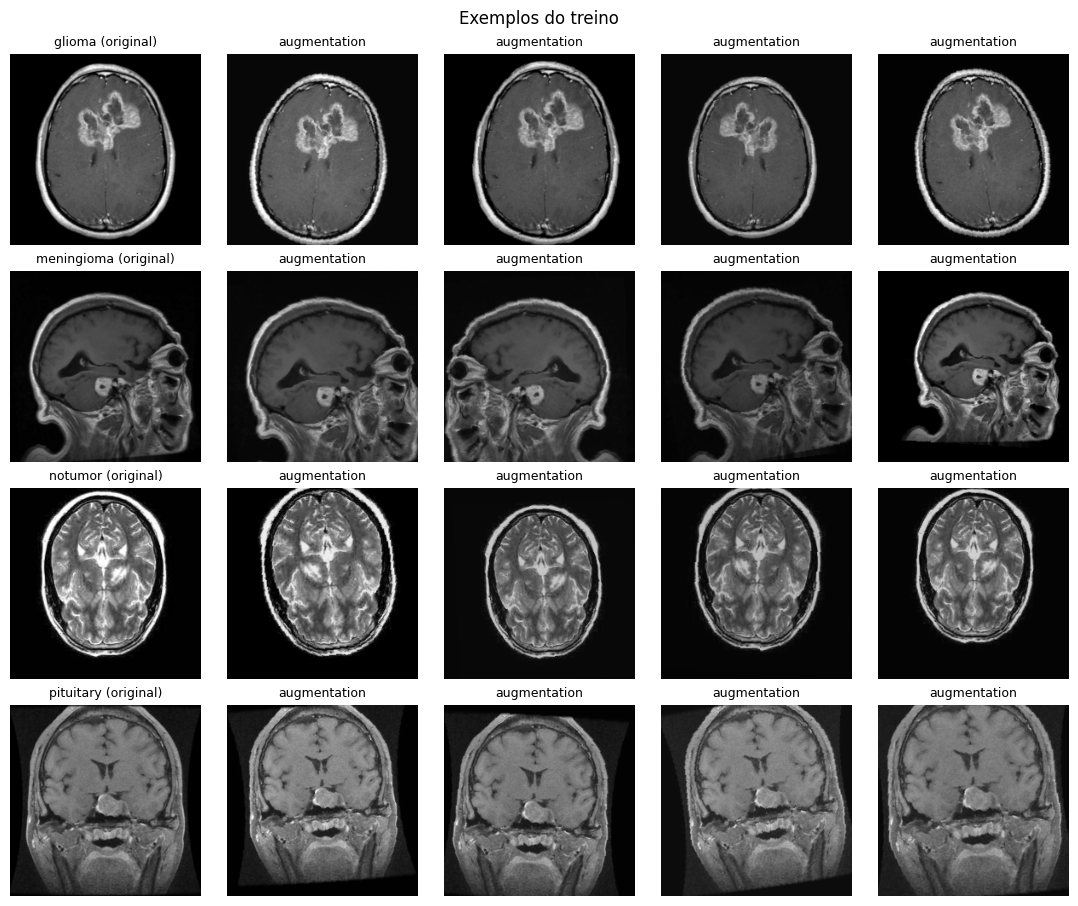

In [11]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]  # ImageNet

train_tf = v2.Compose([
    v2.RandomHorizontalFlip(),
    v2.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.9, 1.1)),
    v2.ColorJitter(brightness=0.2, contrast=0.2),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(MEAN, STD),
])
eval_tf = v2.Compose([
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(MEAN, STD),
])

class TensorImageDataset(Dataset):
    def __init__(self, x, y, transform):
        self.x, self.y, self.transform = x, y, transform
    def __len__(self):
        return len(self.y)
    def __getitem__(self, i):
        return self.transform(self.x[i]), self.y[i]

def make_loader(split, transform, batch_size, shuffle, fraction=1.0, seed=SEED):
    x, y = cache[split]
    if fraction < 1.0:  # subamostra estratificada (só usada para acelerar o grid)
        idx, _ = train_test_split(np.arange(len(y)), train_size=fraction, stratify=y.numpy(), random_state=seed)
        x, y = x[idx], y[idx]
    g = torch.Generator().manual_seed(seed)
    return DataLoader(TensorImageDataset(x, y, transform), batch_size=batch_size, shuffle=shuffle,
                      generator=g, num_workers=2, pin_memory=DEVICE.type == "cuda")

def denorm(img):
    return (img * torch.tensor(STD)[:, None, None] + torch.tensor(MEAN)[:, None, None]).clamp(0, 1).permute(1, 2, 0)

# Mesma imagem de cada classe, sem e com augmentation
x_tr, y_tr = cache["treino"]
idx = [int((y_tr == c).nonzero()[0]) for c in range(len(CLASSES))]
fig, axes = plt.subplots(len(idx), 5, figsize=(11, 2.3 * len(idx)))
for r, i in enumerate(idx):
    axes[r, 0].imshow(x_tr[i].permute(1, 2, 0)); axes[r, 0].set_title(f"{CLASSES[y_tr[i]]} (original)", fontsize=9)
    for c in range(1, 5):
        axes[r, c].imshow(denorm(train_tf(x_tr[i]))); axes[r, c].set_title("augmentation", fontsize=9)
for a in axes.ravel(): a.axis("off")
plt.suptitle("Exemplos do treino"); plt.tight_layout(); plt.show()

3. Modelo: transfer learning com ResNet18

Mesma base do seu desafio: `models.resnet18(weights=ResNet18_Weights.DEFAULT)`, com a camada `fc` original (1000 classes do ImageNet) **substituída por `Dropout → Linear(512, 4)`**. Não há `Flatten` extra: a ResNet já entrega um vetor de 512 números depois do *global average pooling*.

A ResNet18 é uma pilha de blocos: `conv1 → layer1 → layer2 → layer3 → layer4 → fc`. Os primeiros blocos detectam coisas genéricas (bordas, texturas), que servem para qualquer imagem. Os últimos detectam padrões mais específicos do ImageNet (focinhos, rodas), que são os que mais precisam se adaptar a ressonâncias.

O hiperparâmetro `fine_tune` define **até onde** a rede é ajustada:

| `fine_tune` | Treinados | Congelados |
|---|---|---|
| `"fc"` | só a nova cabeça | todo o backbone |
| `"layer4"` | `layer4` + cabeça | `conv1` … `layer3` |
| `"layer3"` | `layer3` + `layer4` + cabeça | `conv1` … `layer2` |

> Por que não liberar a rede inteira, como no Kaggle? Com ~5 mil imagens de treino, ajustar 11 milhões de parâmetros aumenta o risco de decorar. O grid mede até onde vale a pena ir.

**Fine-tuning em duas fases** (correção do item 6):
1. **Aquecimento** (`WARMUP_EPOCHS`): só a cabeça treina. No começo ela é aleatória e produz gradientes grandes; se o backbone estivesse liberado, esses gradientes bagunçariam os filtros pré-treinados.
2. **Fine-tuning:** os blocos escolhidos são liberados, com **learning rate 10× menor** que a cabeça (`BACKBONE_LR_MULT`). A cabeça aprende rápido; o backbone só se ajusta de leve.

Como no seu desafio, as camadas congeladas ficam com o **BatchNorm em modo `eval`** e a rede devolve **logits**, com `CrossEntropyLoss`.

In [12]:
TRAINABLE_BLOCKS = {
    "fc":     {"fc"},
    "layer4": {"layer4", "fc"},
    "layer3": {"layer3", "layer4", "fc"},
}

class TransferResNet18(nn.Module):
    def __init__(self, dropout=0.0, n_classes=4, pretrained=True):
        super().__init__()
        weights = models.ResNet18_Weights.DEFAULT if pretrained else None
        self.backbone = models.resnet18(weights=weights)
        in_features = self.backbone.fc.in_features  # 512
        self.backbone.fc = nn.Sequential(nn.Dropout(dropout), nn.Linear(in_features, n_classes))  # logits
        self.frozen = []
        self.set_trainable("fc")

    def set_trainable(self, fine_tune):
        """Libera para treino só os blocos de `fine_tune`; o resto fica congelado."""
        trainable = TRAINABLE_BLOCKS[fine_tune]
        for name, p in self.backbone.named_parameters():
            p.requires_grad = name.split(".")[0] in trainable
        self.frozen = [m for n, m in self.backbone.named_children() if n not in trainable]
        self.train(self.training)   # reaplica o modo eval nos blocos congelados

    def train(self, mode=True):
        super().train(mode)
        for m in self.frozen:  # BatchNorm congelado mantém as estatísticas do ImageNet
            m.eval()
        return self

    def param_groups(self, fine_tune, lr):
        """Cabeça com lr cheio; blocos convolucionais liberados com lr × BACKBONE_LR_MULT."""
        blocks = TRAINABLE_BLOCKS[fine_tune] - {"fc"}
        head = list(self.backbone.fc.parameters())
        body = [p for n, p in self.backbone.named_parameters() if n.split(".")[0] in blocks]
        groups = [{"params": head, "lr": lr}]
        if body:
            groups.append({"params": body, "lr": lr * BACKBONE_LR_MULT})
        return groups

    @property
    def cam_layer(self):        # última camada convolucional, usada pelo Grad-CAM (6.4)
        return self.backbone.layer4

    def forward(self, x):
        return self.backbone(x)

**Baseline: uma CNN simples treinada do zero.** Serve para responder "quanto o pré-treino no ImageNet ajuda?" (seção 6.5). São 4 blocos `Conv → BatchNorm → ReLU` (×2) `→ MaxPool`, com 32, 64, 128 e 256 filtros. É a arquitetura clássica de aula: cada bloco dobra o número de filtros e divide o tamanho da imagem por 2. Ela tem os mesmos métodos da ResNet (`set_trainable`, `param_groups`, `cam_layer`), então usa o mesmo laço de treino.

In [13]:
class SmallCNN(nn.Module):
    def __init__(self, dropout=0.3, n_classes=4):
        super().__init__()
        def block(i, o):
            return nn.Sequential(
                nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
                nn.Conv2d(o, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
                nn.MaxPool2d(2))
        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128), block(128, 256))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(dropout), nn.Linear(256, n_classes))

    def set_trainable(self, fine_tune):   # treinada do zero: tudo é sempre treinável
        pass

    def param_groups(self, fine_tune, lr):
        return [{"params": list(self.parameters()), "lr": lr}]

    @property
    def cam_layer(self):
        return self.features[-1]

    def forward(self, x):
        return self.head(self.features(x))

def build_model(cfg):
    if cfg.get("model", "resnet18") == "smallcnn":
        return SmallCNN(cfg["dropout"], len(CLASSES)).to(DEVICE)
    return TransferResNet18(cfg["dropout"], len(CLASSES), PRETRAINED).to(DEVICE)

def build_optimizer(cfg, model):
    groups = model.param_groups(cfg["fine_tune"], cfg["lr"])
    if cfg["optimizer"] == "adamw":    # Adam com weight decay "desacoplado" (a forma correta de L2 no Adam)
        return torch.optim.AdamW(groups, lr=cfg["lr"], weight_decay=WEIGHT_DECAY)
    if cfg["optimizer"] == "sgd":
        return torch.optim.SGD(groups, lr=cfg["lr"], momentum=0.9, weight_decay=WEIGHT_DECAY)
    raise ValueError(cfg["optimizer"])

for ft in PARAM_GRID["fine_tune"]:
    m = build_model({"fine_tune": ft, "dropout": 0.0})
    m.set_trainable(ft)
    total = sum(p.numel() for p in m.parameters())
    train = sum(p.numel() for p in m.parameters() if p.requires_grad)
    print(f"fine_tune={ft:7s}: {train:>10,} treináveis de {total:,} ({train / total:.1%})")
m = build_model({"model": "smallcnn", "dropout": 0.3})
print(f"SmallCNN (baseline): {sum(p.numel() for p in m.parameters()):,} parâmetros, todos treináveis")
del m

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 184MB/s]


fine_tune=fc     :      2,052 treináveis de 11,178,564 (0.0%)
fine_tune=layer4 :  8,395,780 treináveis de 11,178,564 (75.1%)
fine_tune=layer3 : 10,495,492 treináveis de 11,178,564 (93.9%)
SmallCNN (baseline): 1,174,244 parâmetros, todos treináveis


### 3.1 Laço de treino com early stopping e scheduler


* **Aquecimento:** nas primeiras `WARMUP_EPOCHS` épocas, `set_trainable("fc")`; depois, `set_trainable(cfg["fine_tune"])`. O otimizador já conhece todos os parâmetros, mas ignora os que estão sem gradiente.
* **`ReduceLROnPlateau`:** se a loss de validação não melhora por 1 época, o learning rate cai para 30%. Passos menores ajudam a "assentar" num mínimo, em vez de oscilar como no Kaggle (0,011 → 0,099 → 0,014).
* **Precisão mista (`autocast`):** na GPU, as contas são feitas em 16 bits onde é seguro, ~2× mais rápido. O `GradScaler` evita que gradientes muito pequenos virem zero.

O resto é o mesmo: guarda os pesos da época com **menor loss de validação** (correção do item 8) e para após `patience` épocas sem melhora.

In [14]:
criterion = nn.CrossEntropyLoss()

def run_epoch(model, loader, optimizer=None, scaler=None):
    training = optimizer is not None
    model.train(training)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
                logits = model(x)
                loss = criterion(logits, y)
            if training:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            total_loss += loss.item() * len(y)
            correct += (logits.argmax(1) == y).sum().item()
            n += len(y)
    return total_loss / n, correct / n

def fit(cfg, max_epochs, patience, train_fraction=1.0, seed=SEED, verbose=False):
    seed_everything(seed)
    model = build_model(cfg)
    optimizer = build_optimizer(cfg, model)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.3, patience=1)
    scaler = torch.amp.GradScaler(DEVICE.type, enabled=USE_AMP)
    train_loader = make_loader("treino", train_tf, BATCH_SIZE, shuffle=True, fraction=train_fraction, seed=seed)
    val_loader = make_loader("validação", eval_tf, 256, shuffle=False)

    history, best = [], {"val_loss": float("inf")}
    best_state, wait = None, 0
    for epoch in range(1, max_epochs + 1):
        # Fase 1 (aquecimento): só a cabeça. Fase 2: os blocos escolhidos no grid.
        ft_now = "fc" if epoch <= WARMUP_EPOCHS else cfg["fine_tune"]
        model.set_trainable(ft_now)

        t0 = time.time()
        lr_now = optimizer.param_groups[0]["lr"]
        tr_loss, tr_acc = run_epoch(model, train_loader, optimizer, scaler)
        va_loss, va_acc = run_epoch(model, val_loader)
        if not np.isfinite(tr_loss):  # divergiu (ex.: lr alto demais)
            print("  loss não finita, interrompendo esta configuração")
            break
        scheduler.step(va_loss)
        history.append({"epoch": epoch, "treinando": ft_now, "lr": lr_now,
                        "train_loss": tr_loss, "train_acc": tr_acc,
                        "val_loss": va_loss, "val_acc": va_acc, "sec": time.time() - t0})
        if verbose:
            print(f"  época {epoch:2d} [{ft_now:6s}] lr {lr_now:.0e} | treino loss {tr_loss:.4f} acc {tr_acc:.3f} | "
                  f"val loss {va_loss:.4f} acc {va_acc:.3f} | {time.time() - t0:.0f}s")
        if va_loss < best["val_loss"]:
            best = history[-1].copy()
            best_state = copy.deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                break
    if best_state is not None:
        model.load_state_dict(best_state)
    model.set_trainable(cfg["fine_tune"])
    return model, pd.DataFrame(history), best

4.Grid Search

Cada combinação de `PARAM_GRID` é treinada com o **treino** e avaliada na **validação**. O **teste não participa**.

O resultado de cada configuração é gravado em `grid_search.csv` assim que termina. Se o Colab desconectar, é só rodar a célula de novo: as configurações já feitas são puladas.

In [15]:
grid = list(ParameterGrid(PARAM_GRID))
done = pd.read_csv(GRID_CSV) if GRID_CSV.exists() else pd.DataFrame()
key = lambda c: json.dumps({k: c[k] for k in sorted(PARAM_GRID)}, sort_keys=True)
done_keys = set(done["config"]) if len(done) else set()

t_grid = time.time()
for i, cfg in enumerate(grid, 1):
    if key(cfg) in done_keys:
        continue
    print(f"[{i}/{len(grid)}] {cfg}")
    t0 = time.time()
    _, hist, best = fit(cfg, GRID_MAX_EPOCHS, GRID_PATIENCE, train_fraction=GRID_TRAIN_FRACTION)
    if best["val_loss"] == float("inf"):
        best = {"epoch": 0, "train_loss": np.nan, "train_acc": np.nan, "val_loss": np.nan, "val_acc": np.nan}
    row = {**cfg, "config": key(cfg), "best_epoch": best["epoch"], "epochs_run": len(hist),
           "train_loss": best["train_loss"], "train_acc": best["train_acc"],
           "val_loss": best["val_loss"], "val_acc": best["val_acc"],
           "max_train_acc": hist["train_acc"].max() if len(hist) else np.nan,
           "minutes": (time.time() - t0) / 60}
    print(f"   -> val loss {row['val_loss']:.4f} | val acc {row['val_acc']:.3f} | "
          f"melhor época {row['best_epoch']} | {row['minutes']:.1f} min")
    done = pd.concat([done, pd.DataFrame([row])], ignore_index=True)
    done.to_csv(GRID_CSV, index=False)

print(f"Grid concluído em {(time.time() - t_grid) / 60:.1f} min")

[1/24] {'dropout': 0.2, 'fine_tune': 'fc', 'lr': 0.001, 'optimizer': 'adamw'}
   -> val loss 0.4382 | val acc 0.850 | melhor época 6 | 0.7 min
[2/24] {'dropout': 0.2, 'fine_tune': 'fc', 'lr': 0.001, 'optimizer': 'sgd'}
   -> val loss 0.4568 | val acc 0.844 | melhor época 6 | 0.7 min
[3/24] {'dropout': 0.2, 'fine_tune': 'fc', 'lr': 0.0001, 'optimizer': 'adamw'}
   -> val loss 0.7692 | val acc 0.756 | melhor época 6 | 0.6 min
[4/24] {'dropout': 0.2, 'fine_tune': 'fc', 'lr': 0.0001, 'optimizer': 'sgd'}
   -> val loss 0.7385 | val acc 0.765 | melhor época 6 | 0.6 min
[5/24] {'dropout': 0.2, 'fine_tune': 'layer4', 'lr': 0.001, 'optimizer': 'adamw'}
   -> val loss 0.1840 | val acc 0.942 | melhor época 5 | 0.7 min
[6/24] {'dropout': 0.2, 'fine_tune': 'layer4', 'lr': 0.001, 'optimizer': 'sgd'}
   -> val loss 0.3425 | val acc 0.882 | melhor época 6 | 0.7 min
[7/24] {'dropout': 0.2, 'fine_tune': 'layer4', 'lr': 0.0001, 'optimizer': 'adamw'}
   -> val loss 0.2966 | val acc 0.905 | melhor época 6 

### 4.1 Ranking das configurações

**Critério de seleção:** menor **loss de validação** (desempate pela acurácia de validação).
A coluna `gap` = acurácia de treino − acurácia de validação na época escolhida. Gap alto indica *overfitting*.

> **Atenção, comparando com o `desafio.py`:** lá havia, logo depois de extrair o vencedor, a linha
> `best_cfg = {"lr": 0.001, "batch_size": 32, "fine_tune": "layer4", "dropout": 0.5, "optimizer": "sgd"}`,
> que **sobrescreve** o resultado do grid com valores fixos. Se o vencedor fosse outro, o treino final usaria a configuração errada sem avisar. Aqui `best_cfg` vem **só** do ranking.

In [16]:
results = pd.read_csv(GRID_CSV)
results = results[results["config"].isin({key(c) for c in grid})].copy()
results["gap"] = results["train_acc"] - results["val_acc"]
results = results.sort_values(["val_loss", "val_acc"], ascending=[True, False]).reset_index(drop=True)
results.index += 1

best_cfg = {k: results.loc[1, k] for k in PARAM_GRID}
best_cfg = {k: (v.item() if hasattr(v, "item") else v) for k, v in best_cfg.items()}
best_cfg["lr"], best_cfg["dropout"] = float(best_cfg["lr"]), float(best_cfg["dropout"])

print("🏆 Melhor combinação (menor loss de validação):")
for k, v in best_cfg.items():
    print(f"   {k:10s} = {v}")

cols = ["lr", "fine_tune", "dropout", "optimizer", "best_epoch",
        "train_loss", "val_loss", "train_acc", "val_acc", "gap"]
fmt = {"lr": "{:.0e}", "train_loss": "{:.4f}", "val_loss": "{:.4f}",
       "train_acc": "{:.3f}", "val_acc": "{:.3f}", "gap": "{:+.3f}"}
(results[cols].head(10).style.format(fmt)
    .background_gradient(subset=["val_acc"], cmap="Greens")
    .background_gradient(subset=["gap"], cmap="Reds"))

🏆 Melhor combinação (menor loss de validação):
   lr         = 0.001
   fine_tune  = layer3
   dropout    = 0.2
   optimizer  = adamw


,lr,fine_tune,dropout,optimizer,best_epoch,train_loss,val_loss,train_acc,val_acc,gap
1,1e-03,layer3,0.200000,adamw,6,0.0741,0.1744,0.974,0.945,+0.029
2,1e-03,layer4,0.500000,adamw,6,0.1128,0.1749,0.961,0.947,+0.014
3,1e-03,layer3,0.500000,adamw,6,0.0766,0.1755,0.972,0.940,+0.032
4,1e-03,layer4,0.200000,adamw,5,0.1347,0.1840,0.948,0.942,+0.006
5,1e-04,layer3,0.200000,adamw,6,0.2664,0.2699,0.906,0.898,+0.008
6,1e-04,layer3,0.500000,adamw,6,0.3163,0.2928,0.895,0.898,-0.003
7,1e-04,layer4,0.200000,adamw,6,0.3033,0.2966,0.895,0.905,-0.010
8,1e-04,layer4,0.500000,adamw,6,0.3564,0.3204,0.876,0.894,-0.018
9,1e-03,layer3,0.200000,sgd,6,0.3698,0.3340,0.862,0.872,-0.009
10,1e-03,layer3,0.500000,sgd,6,0.4165,0.3402,0.839,0.867,-0.029


### 4.2 Generalização: o melhor no treino é o melhor na validação?

Cada ponto é uma configuração. Pontos **acima da diagonal** (treino ≫ validação) estão decorando o treino.

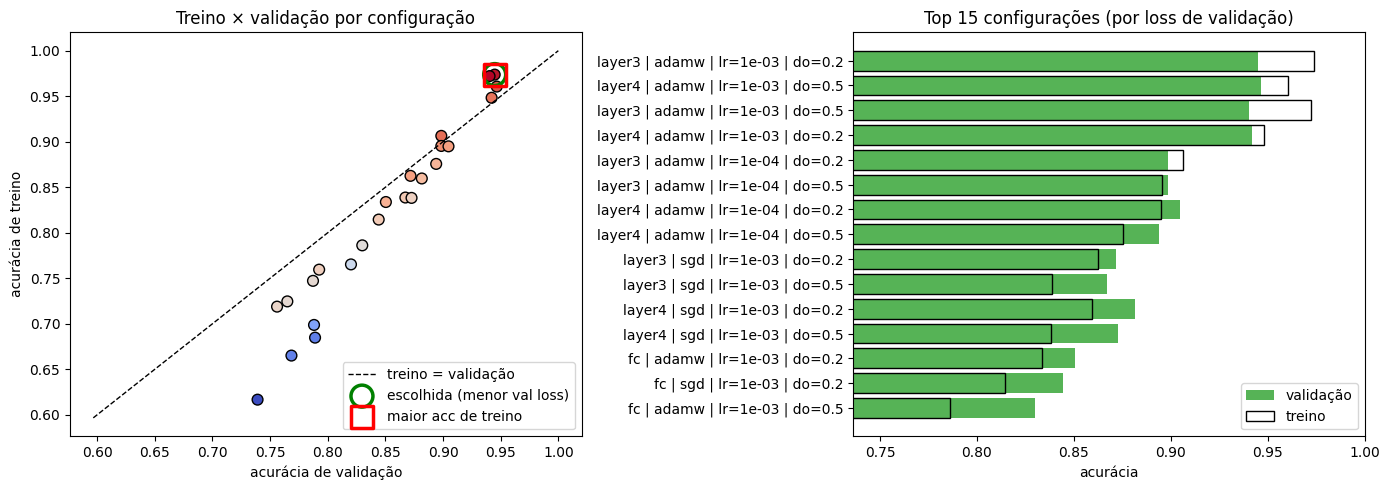

,fine_tune,optimizer,lr,dropout,max_train_acc,val_acc,val_loss
Escolhida (menor val loss),layer3,adamw,0.001,0.2,0.973727,0.944791,0.17438
Maior acurácia de treino,layer3,adamw,0.001,0.2,0.973727,0.944791,0.17438


In [17]:
by_train = results.sort_values("max_train_acc", ascending=False).iloc[0]
best_row = results.loc[1]

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].scatter(results["val_acc"], results["train_acc"], c=results["gap"], cmap="coolwarm", s=60, edgecolor="k")
lim = [min(results[["train_acc", "val_acc"]].min()) - 0.02, 1.0]
ax[0].plot(lim, lim, "k--", lw=1, label="treino = validação")
ax[0].scatter(best_row["val_acc"], best_row["train_acc"], s=250, facecolor="none", edgecolor="green", lw=2.5,
              label="escolhida (menor val loss)")
ax[0].scatter(by_train["val_acc"], by_train["train_acc"], s=250, marker="s", facecolor="none", edgecolor="red",
              lw=2.5, label="maior acc de treino")
ax[0].set(xlabel="acurácia de validação", ylabel="acurácia de treino", title="Treino × validação por configuração")
ax[0].legend(loc="lower right")

top = results.head(15).iloc[::-1]
labels = [f"{r.fine_tune} | {r.optimizer} | lr={r.lr:.0e} | do={r.dropout}" for r in top.itertuples()]
ax[1].barh(labels, top["val_acc"], color="tab:green", alpha=0.8, label="validação")
ax[1].barh(labels, top["train_acc"], color="none", edgecolor="k", label="treino")
ax[1].set(xlabel="acurácia", title="Top 15 configurações (por loss de validação)",
          xlim=(max(0.4, top[["val_acc", "train_acc"]].min().min() - 0.05), 1.0))
ax[1].legend(loc="lower right")
plt.tight_layout(); plt.savefig(OUT_DIR / "generalizacao.png", dpi=150); plt.show()

comp = pd.DataFrame([best_row, by_train], index=["Escolhida (menor val loss)", "Maior acurácia de treino"])
comp[["fine_tune", "optimizer", "lr", "dropout", "max_train_acc", "val_acc", "val_loss"]]

### 4.3 Efeito de cada hiperparâmetro

Média da acurácia e da loss de validação, agrupando por cada hiperparâmetro (média sobre todas as combinações dos demais). Aqui você consegue ver, por exemplo, se liberar `layer3` compensa em relação a `layer4`.

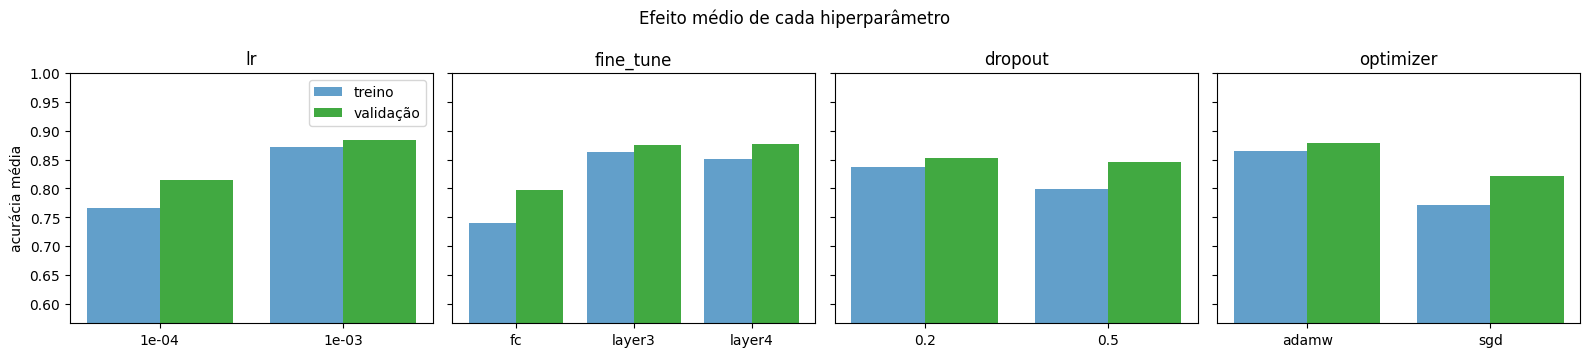

In [18]:
fig, axes = plt.subplots(1, len(PARAM_GRID), figsize=(4 * len(PARAM_GRID), 3.6), sharey=True)
for ax, hp in zip(axes, PARAM_GRID):
    g = results.groupby(hp)[["val_acc", "train_acc"]].mean()
    x = np.arange(len(g))
    ax.bar(x - 0.2, g["train_acc"], 0.4, label="treino", color="tab:blue", alpha=0.7)
    ax.bar(x + 0.2, g["val_acc"], 0.4, label="validação", color="tab:green", alpha=0.9)
    ax.set_xticks(x, [f"{v:.0e}" if hp == "lr" else str(v) for v in g.index])
    ax.set_title(hp)
    ax.set_ylim(max(0.4, results[["val_acc", "train_acc"]].min().min() - 0.05), 1.0)
axes[0].set_ylabel("acurácia média"); axes[0].legend()
plt.suptitle("Efeito médio de cada hiperparâmetro"); plt.tight_layout()
plt.savefig(OUT_DIR / "efeito_hiperparametros.png", dpi=150); plt.show()

pd.concat({hp: results.groupby(hp)[["val_loss", "val_acc", "gap"]].mean() for hp in PARAM_GRID}).style.format("{:.3f}")

5.Treino Final do melhor modelo (com 3 sementes)

A configuração vencedora é treinada com o **treino completo** e mais épocas, mantendo o early stopping na **validação**.

**Novidade:** o treino é repetido com `FINAL_SEEDS = [42, 7, 2026]`. A semente muda a inicialização da cabeça, a ordem dos lotes e o sorteio do augmentation. Se o resultado varia muito entre sementes, um número único como "99,24%" diz pouco.

O modelo salvo é o da semente com **menor loss de validação**. Escolher pela validação mantém o teste intocado.

In [19]:
print("Treinando:", best_cfg)
runs = []
for s in FINAL_SEEDS:
    print(f"\n=== semente {s} ===")
    model, hist, best = fit(best_cfg, FINAL_MAX_EPOCHS, FINAL_PATIENCE, seed=s, verbose=True)
    hist.to_csv(OUT_DIR / f"historico_semente_{s}.csv", index=False)
    runs.append({"seed": s, "model": model, "history": hist, "best": best})

final_run = min(runs, key=lambda r: r["best"]["val_loss"])
best_model, history, best_epoch_info = final_run["model"], final_run["history"], final_run["best"]
torch.save({"config": best_cfg, "state_dict": best_model.state_dict(), "classes": CLASSES,
            "img_size": IMG_SIZE, "seed": final_run["seed"]}, OUT_DIR / "melhor_modelo.pt")
print(f"\nModelo salvo: semente {final_run['seed']}, melhor época {best_epoch_info['epoch']}")

Treinando: {'lr': 0.001, 'fine_tune': 'layer3', 'dropout': 0.2, 'optimizer': 'adamw'}

=== semente 42 ===
  época  1 [fc    ] lr 1e-03 | treino loss 0.7918 acc 0.688 | val loss 0.5600 acc 0.792 | 12s
  época  2 [layer3] lr 1e-03 | treino loss 0.3134 acc 0.883 | val loss 0.2055 acc 0.931 | 12s
  época  3 [layer3] lr 1e-03 | treino loss 0.1516 acc 0.947 | val loss 0.1562 acc 0.949 | 12s
  época  4 [layer3] lr 1e-03 | treino loss 0.0973 acc 0.966 | val loss 0.1135 acc 0.963 | 12s
  época  5 [layer3] lr 1e-03 | treino loss 0.0846 acc 0.971 | val loss 0.0995 acc 0.972 | 12s
  época  6 [layer3] lr 1e-03 | treino loss 0.0584 acc 0.979 | val loss 0.1216 acc 0.969 | 12s
  época  7 [layer3] lr 1e-03 | treino loss 0.0499 acc 0.983 | val loss 0.1584 acc 0.958 | 12s
  época  8 [layer3] lr 3e-04 | treino loss 0.0336 acc 0.989 | val loss 0.0923 acc 0.979 | 12s
  época  9 [layer3] lr 3e-04 | treino loss 0.0230 acc 0.993 | val loss 0.0958 acc 0.977 | 12s
  época 10 [layer3] lr 3e-04 | treino loss 0.018

# 5.1 Curvas de aprendizado

Linhas fortes = semente escolhida; linhas claras = as outras sementes (só validação). A faixa cinza marca o **aquecimento** (só a cabeça treinando). O terceiro painel mostra o learning rate da cabeça caindo pelo `ReduceLROnPlateau`.

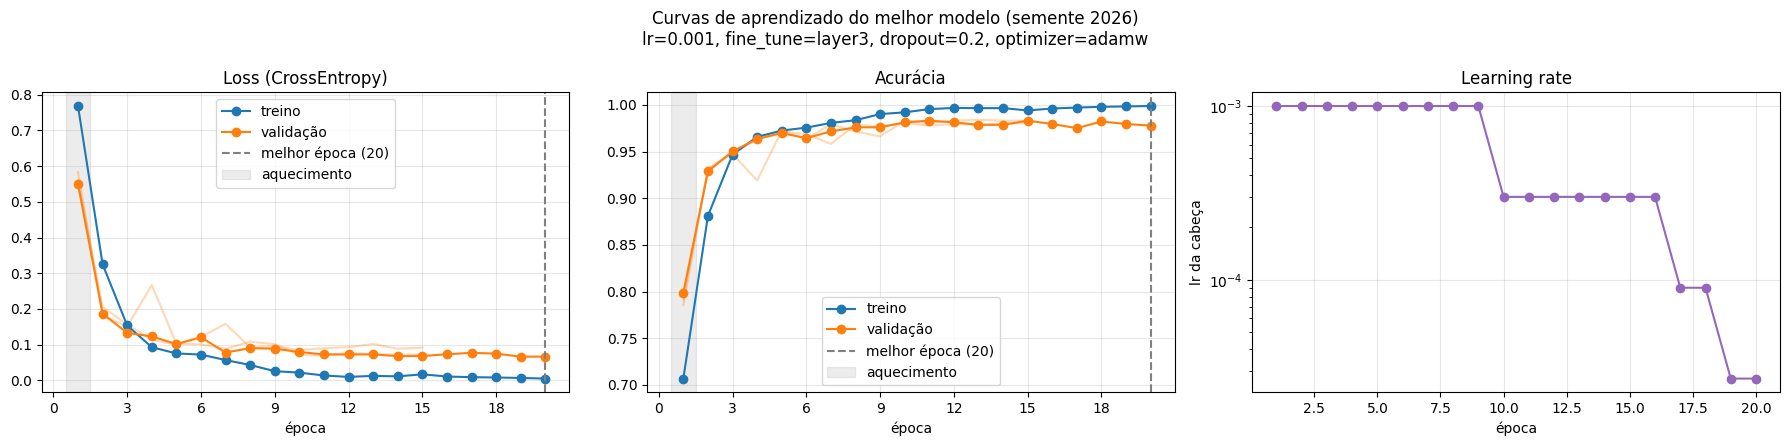

In [20]:
be = best_epoch_info["epoch"]
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
for a, metric, title in [(ax[0], "loss", "Loss (CrossEntropy)"), (ax[1], "acc", "Acurácia")]:
    for r in runs:
        if r is not final_run:
            a.plot(r["history"]["epoch"], r["history"][f"val_{metric}"], color="tab:orange", alpha=0.3)
    a.plot(history["epoch"], history[f"train_{metric}"], "o-", label="treino")
    a.plot(history["epoch"], history[f"val_{metric}"], "o-", label="validação")
    a.axvline(be, color="gray", ls="--", label=f"melhor época ({be})")
    if best_cfg["fine_tune"] != "fc":
        a.axvspan(0.5, WARMUP_EPOCHS + 0.5, color="gray", alpha=0.15, label="aquecimento")
    a.set(xlabel="época", title=title); a.grid(alpha=0.3); a.legend()
    a.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax[2].plot(history["epoch"], history["lr"], "o-", color="tab:purple")
ax[2].set(xlabel="época", ylabel="lr da cabeça", title="Learning rate", yscale="log"); ax[2].grid(alpha=0.3)
cfg_txt = ", ".join(f"{k}={v}" for k, v in best_cfg.items())
plt.suptitle(f"Curvas de aprendizado do melhor modelo (semente {final_run['seed']})\n{cfg_txt}")
plt.tight_layout(); plt.savefig(OUT_DIR / "curvas_aprendizado.png", dpi=150); plt.show()

# 6. Avaliação final

Os conjuntos são avaliados **nas mesmas condições** (modo `eval`, sem augmentation, sem dropout).
É a **primeira e única vez** que o conjunto de teste é usado.

### 6.1 Treino × validação × teste

,loss,acurácia,imagens
treino,0.0027,99.90%,4872
validação,0.0664,97.77%,1123
teste,0.0902,97.32%,1081


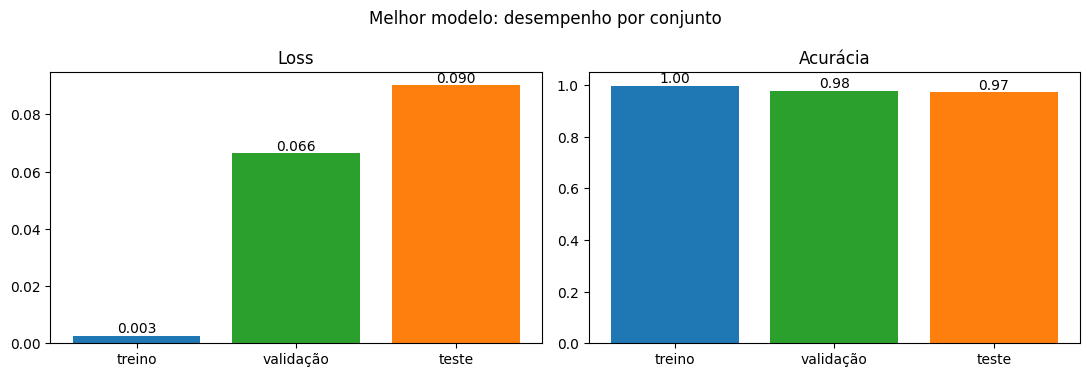

In [21]:
@torch.no_grad()
def predict_split(model, split):
    """Devolve loss, acurácia, probabilidades e rótulos verdadeiros de um conjunto."""
    model.eval()
    probs, ys = [], []
    for x, y in make_loader(split, eval_tf, 256, shuffle=False):
        with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
            logits = model(x.to(DEVICE))
        probs.append(torch.softmax(logits.float(), 1).cpu())
        ys.append(y)
    probs, ys = torch.cat(probs), torch.cat(ys)
    loss = F.nll_loss(torch.log(probs.clamp_min(1e-12)), ys).item()
    acc = (probs.argmax(1) == ys).float().mean().item()
    return loss, acc, probs.numpy(), ys.numpy()

final = {}
for split in ["treino", "validação", "teste"]:
    loss, acc, probs, ys = predict_split(best_model, split)
    final[split] = {"loss": loss, "acurácia": acc, "imagens": len(ys)}
    if split == "teste":
        probs_test, trues = probs, ys
preds = probs_test.argmax(1)

final_df = pd.DataFrame(final).T
final_df["imagens"] = final_df["imagens"].astype(int)
final_df.to_csv(OUT_DIR / "metricas_finais.csv")
display(final_df.style.format({"loss": "{:.4f}", "acurácia": "{:.2%}"}))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
colors = ["tab:blue", "tab:green", "tab:orange"]
for a, m in zip(ax, ["loss", "acurácia"]):
    bars = a.bar(final_df.index, final_df[m].astype(float), color=colors)
    a.bar_label(bars, fmt="%.3f" if m == "loss" else "%.2f")
    a.set_title(m.capitalize())
ax[1].set_ylim(0, 1.05)
plt.suptitle("Melhor modelo: desempenho por conjunto"); plt.tight_layout()
plt.savefig(OUT_DIR / "metricas_finais.png", dpi=150); plt.show()

### 6.2 Estabilidade entre sementes

Mesma configuração, três treinos. O **desvio padrão** mostra quanto o resultado depende do acaso. Ao comparar dois modelos, diferenças menores que esse desvio não significam muita coisa.

In [22]:
por_semente = []
for r in runs:
    _, va_acc, _, _ = predict_split(r["model"], "validação")
    _, te_acc, _, _ = predict_split(r["model"], "teste")
    por_semente.append({"semente": r["seed"], "melhor época": r["best"]["epoch"],
                        "val loss": r["best"]["val_loss"], "val acc": va_acc, "teste acc": te_acc})
por_semente = pd.DataFrame(por_semente).set_index("semente")
por_semente.to_csv(OUT_DIR / "metricas_por_semente.csv")
display(por_semente.style.format({"val loss": "{:.4f}", "val acc": "{:.2%}", "teste acc": "{:.2%}"}))

te_mean, te_std = por_semente["teste acc"].mean(), por_semente["teste acc"].std()
print(f"Acurácia de teste: {te_mean:.2%} ± {te_std:.2%} (média ± desvio, {len(runs)} sementes)")

,melhor época,val loss,val acc,teste acc
semente,,,,
42,10,0.0849,98.04%,97.59%
7,10,0.0705,98.31%,97.22%
2026,20,0.0664,97.77%,97.32%


Acurácia de teste: 97.38% ± 0.19% (média ± desvio, 3 sementes)


### 6.3 Relatório por classe, matriz de confusão e erros

Agora com os **nomes** das classes. Em tumores, olhe principalmente a **sensibilidade (recall)**: um glioma classificado como `notumor` é um erro muito mais grave que confundir dois tipos de tumor.

              precision    recall  f1-score   support

      glioma      0.980     0.976     0.978       255
  meningioma      0.974     0.942     0.957       274
     notumor      0.952     0.992     0.972       260
   pituitary      0.986     0.983     0.985       292

    accuracy                          0.973      1081
   macro avg      0.973     0.973     0.973      1081
weighted avg      0.973     0.973     0.973      1081



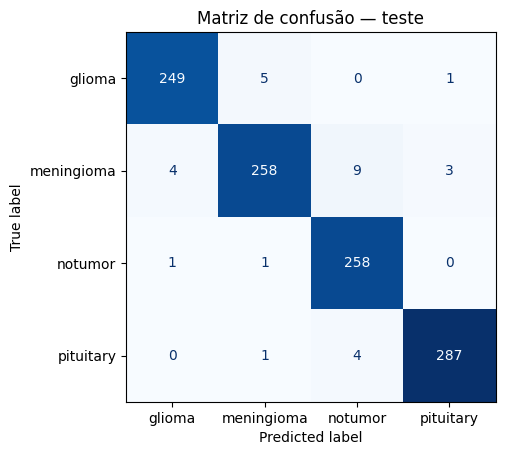

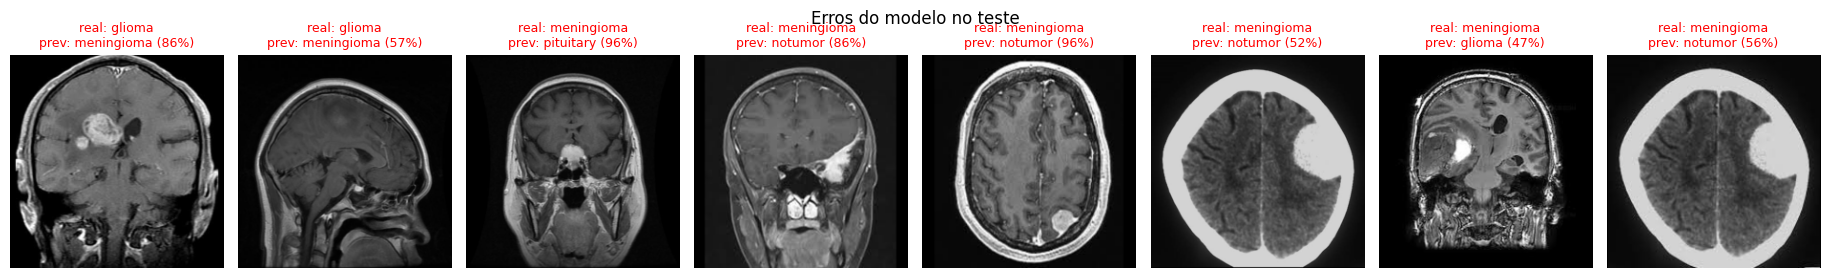

In [23]:
print(classification_report(trues, preds, target_names=CLASSES, digits=3))
ConfusionMatrixDisplay(confusion_matrix(trues, preds), display_labels=CLASSES).plot(cmap="Blues", colorbar=False)
plt.title("Matriz de confusão — teste"); plt.show()

x_test, y_test = cache["teste"]
wrong = np.where(preds != trues)[0][:8]
if len(wrong):
    fig, axes = plt.subplots(1, len(wrong), figsize=(2.3 * len(wrong), 2.8))
    for ax, i in zip(np.atleast_1d(axes), wrong):
        ax.imshow(x_test[i].permute(1, 2, 0))
        ax.set_title(f"real: {CLASSES[trues[i]]}\nprev: {CLASSES[preds[i]]} ({probs_test[i].max():.0%})",
                     fontsize=9, color="red")
        ax.axis("off")
    plt.suptitle("Erros do modelo no teste"); plt.tight_layout(); plt.show()
else:
    print("Nenhum erro no teste.")

## 6.4 Grad-CAM: para onde a CNN está olhando?

Uma acurácia alta não garante que o modelo usa a informação **certa**. Ele poderia, por exemplo, ter aprendido que as imagens de uma fonte (com uma borda ou um contraste típico) são sempre da mesma classe.

**Como funciona o Grad-CAM:**
1. Pegamos os **mapas de ativação** da última camada convolucional (`layer4`: 512 mapas de 7×7).
2. Calculamos o **gradiente** da pontuação da classe prevista em relação a cada mapa. Isso diz quanto cada mapa "empurra" a decisão.
3. Fazemos a média ponderada dos mapas por esses gradientes, ficamos só com a parte positiva (`ReLU`) e ampliamos para 224×224.

O resultado é um mapa de calor: **vermelho = regiões que mais pesaram na decisão**. O esperado é calor sobre o tumor (ou sobre o tecido cerebral, no caso de `notumor`). Calor nas bordas, no fundo preto ou em textos/marcas da imagem é um sinal de alerta.

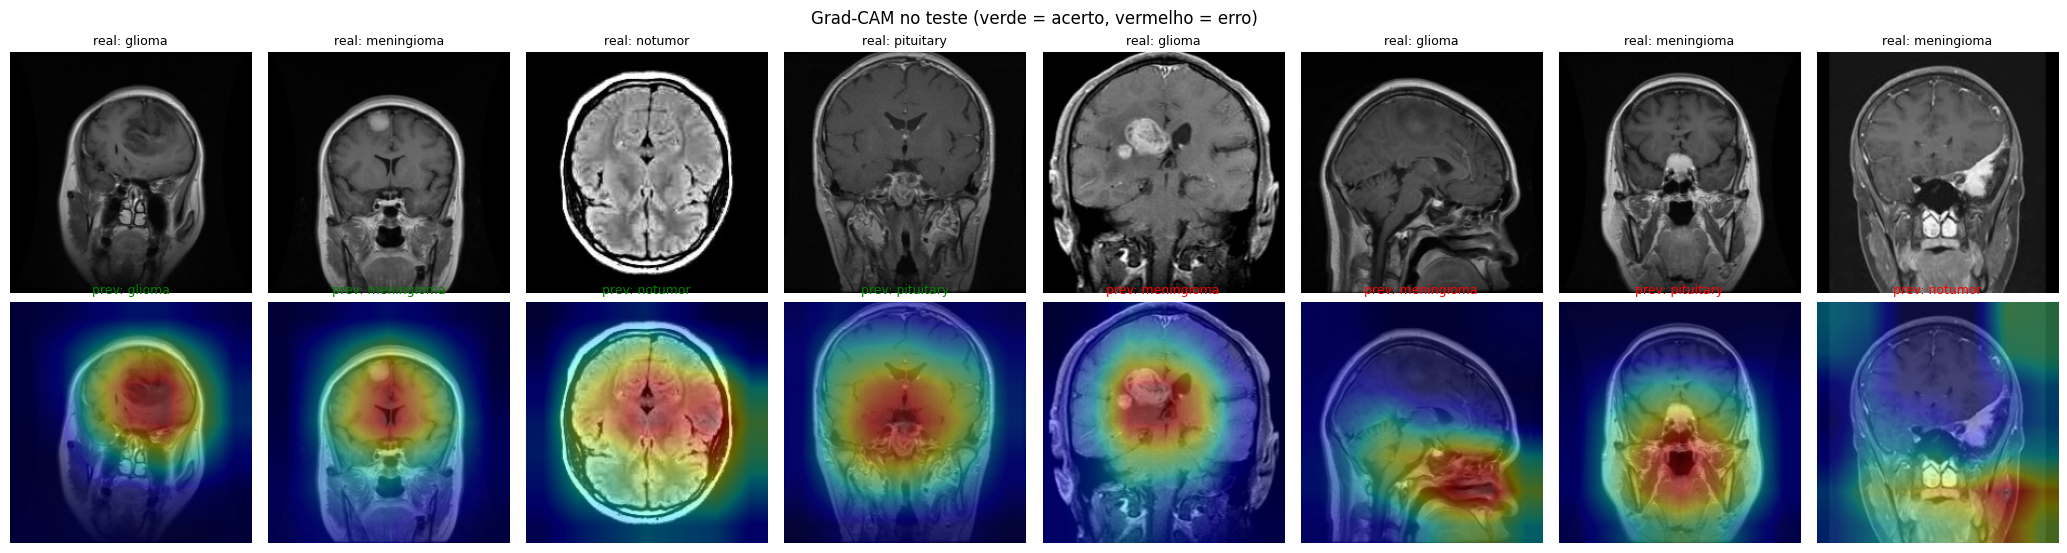

In [24]:
def grad_cam(model, x):
    """Grad-CAM da classe prevista para um lote x (já normalizado). Devolve mapas (B, H, W) em 0–1."""
    model.eval()
    store = {}
    def fwd_hook(module, inp, out):
        store["acts"] = out
        out.register_hook(lambda g: store.__setitem__("grads", g))
    handle = model.cam_layer.register_forward_hook(fwd_hook)
    try:
        x = x.to(DEVICE).clone().requires_grad_(True)   # garante o caminho do gradiente mesmo com backbone congelado
        with torch.enable_grad():
            logits = model(x)
            cls = logits.argmax(1)
            model.zero_grad(set_to_none=True)
            logits.gather(1, cls[:, None]).sum().backward()
    finally:
        handle.remove()
    weights = store["grads"].mean(dim=(2, 3), keepdim=True)            # importância de cada mapa
    cam = F.relu((weights * store["acts"]).sum(1, keepdim=True))        # média ponderada
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[:, 0]
    cam = cam - cam.amin(dim=(1, 2), keepdim=True)
    cam = cam / cam.amax(dim=(1, 2), keepdim=True).clamp_min(1e-8)
    return cam.detach().cpu().numpy(), cls.cpu().numpy()

# 1 acerto por classe + até 4 erros
rng = np.random.default_rng(SEED)
acertos = [int(rng.choice(np.where((preds == trues) & (trues == c))[0]))
           for c in range(len(CLASSES)) if ((preds == trues) & (trues == c)).any()]
idx = [int(i) for i in acertos + list(wrong[:4])]
cams, cls = grad_cam(best_model, eval_tf(x_test[idx]))

fig, axes = plt.subplots(2, len(idx), figsize=(2.6 * len(idx), 5.6), squeeze=False)
for k, i in enumerate(idx):
    img = x_test[i].permute(1, 2, 0).numpy()
    cor = "green" if preds[i] == trues[i] else "red"
    axes[0, k].imshow(img); axes[0, k].set_title(f"real: {CLASSES[trues[i]]}", fontsize=9)
    axes[1, k].imshow(img); axes[1, k].imshow(cams[k], cmap="jet", alpha=0.4)
    axes[1, k].set_title(f"prev: {CLASSES[cls[k]]}", fontsize=9, color=cor)
for a in axes.ravel(): a.axis("off")
plt.suptitle("Grad-CAM no teste (verde = acerto, vermelho = erro)"); plt.tight_layout()
plt.savefig(OUT_DIR / "grad_cam.png", dpi=150); plt.show()

### 6.5 Baseline: quanto o pré-treino ajuda?

A `SmallCNN` (seção 3) é treinada **do zero**, com a mesma divisão, o mesmo augmentation e o mesmo early stopping. Fica claro o ganho real do transfer learning.

Também colocamos na tabela o número do notebook do Kaggle. **Ele não é diretamente comparável:** foi medido num teste que tinha imagens repetidas do treino (seção 2.2). A diferença entre ele e os nossos números estima o quanto o vazamento inflava o resultado.

In [25]:
baseline_cfg = {"model": "smallcnn", "lr": 1e-3, "fine_tune": "fc", "dropout": 0.3, "optimizer": "adamw"}
print("Treinando baseline:", baseline_cfg)
baseline_model, baseline_hist, baseline_best = fit(baseline_cfg, BASELINE_MAX_EPOCHS, FINAL_PATIENCE, verbose=True)
_, base_val_acc, _, _ = predict_split(baseline_model, "validação")
_, base_test_acc, _, _ = predict_split(baseline_model, "teste")

comparacao = pd.DataFrame([
    {"modelo": "Kaggle: Xception, pastas originais (com vazamento)", "acurácia de teste": "99,24% (relatado)"},
    {"modelo": "CNN simples do zero (baseline), divisão por grupo", "acurácia de teste": f"{base_test_acc:.2%}"},
    {"modelo": f"ResNet18 transfer learning, divisão por grupo ({len(runs)} sementes)",
     "acurácia de teste": f"{te_mean:.2%} ± {te_std:.2%}"},
]).set_index("modelo")
comparacao.to_csv(OUT_DIR / "comparacao.csv")
comparacao

Treinando baseline: {'model': 'smallcnn', 'lr': 0.001, 'fine_tune': 'fc', 'dropout': 0.3, 'optimizer': 'adamw'}
  época  1 [fc    ] lr 1e-03 | treino loss 0.9061 acc 0.632 | val loss 1.9484 acc 0.495 | 16s
  época  2 [fc    ] lr 1e-03 | treino loss 0.7242 acc 0.717 | val loss 0.7582 acc 0.632 | 16s
  época  3 [fc    ] lr 1e-03 | treino loss 0.6272 acc 0.768 | val loss 0.8337 acc 0.671 | 15s
  época  4 [fc    ] lr 1e-03 | treino loss 0.5590 acc 0.788 | val loss 1.2452 acc 0.635 | 15s
  época  5 [fc    ] lr 3e-04 | treino loss 0.4572 acc 0.833 | val loss 0.4743 acc 0.832 | 15s
  época  6 [fc    ] lr 3e-04 | treino loss 0.4417 acc 0.838 | val loss 0.4225 acc 0.849 | 15s
  época  7 [fc    ] lr 3e-04 | treino loss 0.4179 acc 0.848 | val loss 0.3918 acc 0.864 | 15s
  época  8 [fc    ] lr 3e-04 | treino loss 0.4061 acc 0.850 | val loss 0.4301 acc 0.845 | 15s
  época  9 [fc    ] lr 3e-04 | treino loss 0.4066 acc 0.854 | val loss 0.5169 acc 0.825 | 15s
  época 10 [fc    ] lr 9e-05 | treino loss

,acurácia de teste
modelo,
"Kaggle: Xception, pastas originais (com vazamento)","99,24% (relatado)"
"CNN simples do zero (baseline), divisão por grupo",91.21%
"ResNet18 transfer learning, divisão por grupo (3 sementes)",97.38% ± 0.19%


 ##7. Resumo 

In [26]:
tr, va, te = final["treino"], final["validação"], final["teste"]
gap_tv = tr["acurácia"] - va["acurácia"]
gap_vt = va["acurácia"] - te["acurácia"]

print("DADOS")
print(f"  • {len(df)} imagens após remover {conflito.sum()} com rótulos conflitantes")
print(f"  • {len(vazadas)} de {n_test_orig} imagens do Testing original tinham cópia quase idêntica no Training")
print("\nMELHOR COMBINAÇÃO DE HIPERPARÂMETROS")
for k, v in best_cfg.items():
    print(f"  • {k}: {v}")
print(f"\nGrid: {len(results)} configurações | critério: menor loss de validação")
print("\nDESEMPENHO DO MELHOR MODELO")
for s, m in final.items():
    print(f"  • {s:10s} loss = {m['loss']:.4f} | acurácia = {m['acurácia']:.2%}")
print(f"  • teste em {len(runs)} sementes: {te_mean:.2%} ± {te_std:.2%}")
print(f"  • baseline (CNN do zero): {base_test_acc:.2%}")
print(f"\nGap treino − validação: {gap_tv:+.2%}")
print(f"Gap validação − teste:  {gap_vt:+.2%}")

if by_train["config"] != best_row["config"]:
    print(f"\nA configuração com MAIOR acurácia de treino ({by_train['max_train_acc']:.2%}) teve "
          f"{by_train['val_acc']:.2%} na validação, contra {best_row['val_acc']:.2%} da escolhida.")
else:
    print("\nA configuração com maior acurácia de treino coincidiu com a de menor loss de validação.")

if abs(gap_vt) < 0.03:
    print("Validação e teste ficaram próximos: a validação foi uma boa estimativa do desempenho em dados novos.")
else:
    print("Validação e teste divergiram mais de 3 p.p.: vale discutir a variância do conjunto de validação.")

DADOS
  • 7076 imagens após remover 124 com rótulos conflitantes
  • 714 de 1600 imagens do Testing original tinham cópia quase idêntica no Training

MELHOR COMBINAÇÃO DE HIPERPARÂMETROS
  • lr: 0.001
  • fine_tune: layer3
  • dropout: 0.2
  • optimizer: adamw

Grid: 24 configurações | critério: menor loss de validação

DESEMPENHO DO MELHOR MODELO
  • treino     loss = 0.0027 | acurácia = 99.90%
  • validação  loss = 0.0664 | acurácia = 97.77%
  • teste      loss = 0.0902 | acurácia = 97.32%
  • teste em 3 sementes: 97.38% ± 0.19%
  • baseline (CNN do zero): 91.21%

Gap treino − validação: +2.12%
Gap validação − teste:  +0.46%

A configuração com maior acurácia de treino coincidiu com a de menor loss de validação.
Validação e teste ficaram próximos: a validação foi uma boa estimativa do desempenho em dados novos.


In [27]:
!zip -qr resultados.zip resultados_tumor_mri

In [28]:
import shutil, os

os.makedirs("/kaggle/working/modelo_tumor_mri", exist_ok=True)
shutil.copy("resultados_tumor_mri/melhor_modelo.pt",
            "/kaggle/working/modelo_tumor_mri/melhor_modelo.pt")
print("Modelo salvo em /kaggle/working!")

Modelo salvo em /kaggle/working!
